In [1]:
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scienceplots

from nanosurrogate.env import setup_gpu_env
setup_gpu_env()

from tensorflow.keras.models import load_model
from nanosurrogate.models import HurdleSurrogate
from nanosurrogate.data import add_physics_features
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from itertools import combinations

# Adjust path
MODEL_DIR = Path("../models/hurdle_baseline")
if not MODEL_DIR.exists():
    MODEL_DIR = Path("models/hurdle_baseline")

# 1. Load model
clf = load_model(MODEL_DIR / "classifier_model.keras")
reg = load_model(MODEL_DIR / "regressor_model.keras")

# 2. load scaler & parameter
with open(MODEL_DIR / "scalers.pkl", "rb") as f:
    scaler_data = pickle.load(f)

x_scaler = scaler_data["x_scaler"]
y_scaler = scaler_data["y_scaler"]
scale_factor = scaler_data["scale_factor"]
blockade_threshold = scaler_data["blockade_threshold"]

# 3. train history & untoched test set
with open(MODEL_DIR / "training_history.pkl", "rb") as f:
    history = pickle.load(f)

test_data = np.load(MODEL_DIR / "test_data.npz")
X_test_raw    = test_data["X_test_raw"]
X_test_scaled = test_data["X_test_scaled"]
y_test_class  = test_data["y_test_class"].flatten()
y_test_raw    = test_data["y_test_raw"].flatten()
y_test_trans  = test_data["y_test_trans"].flatten()
weights_test  = test_data["weights_test"].flatten()

# 4. Init Combined Hurdle-Modell
surrogate = HurdleSurrogate(classifier=clf, regressor=reg, x_scaler=x_scaler, y_scaler=y_scaler, scale_factor=scale_factor)

print(f"Models loaded from: {MODEL_DIR.resolve()}")
print(f"Test Size: {len(X_test_raw)} Samples ({np.mean(y_test_class == 0)*100:.1f}% blocked)")

I0000 00:00:1794571259.305228  374461 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794571259.344868  374461 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794571260.278488  374461 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


✅ SUCCESS: TensorFlow is using NVIDIA GeForce RTX 3060 Ti


I0000 00:00:1794571260.740132  374461 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5590 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.6


Models loaded from: /home/jonasmensing/projects/nanosurrogate/models/hurdle_baseline
Test Size: 2100 Samples (9.8% blocked)


Best Val-Loss Regressor: 0.003846 (in epoch 259)


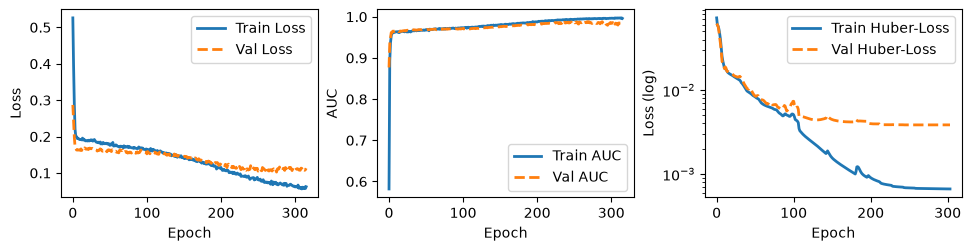

In [2]:
fig, axes = plt.subplots(1, 3, layout='constrained')
fig.set_figwidth(fig.get_figwidth()*1.5)
fig.set_figheight(fig.get_figheight()*0.5)

hist_clf = history["classifier"]
hist_reg = history["regressor"]

# --- Plot 1: Classifier Loss ---
if "bypass" not in hist_clf:
    axes[0].plot(hist_clf["loss"], label="Train Loss", lw=2)
    axes[0].plot(hist_clf["val_loss"], label="Val Loss", lw=2, linestyle="--")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # --- Plot 2: Classifier AUC ---
    axes[1].plot(hist_clf["auc"], label="Train AUC", lw=2)
    axes[1].plot(hist_clf["val_auc"], label="Val AUC", lw=2, linestyle="--")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].legend()
else:
    axes[0].text(0.5, 0.5, "Classifier Bypass aktiv\n(Fast 100% leitend)", ha="center", va="center")
    axes[1].axis("off")

# --- Plot 3: Regressor Loss (Log-Skala für feine Unterschiede) ---
axes[2].plot(hist_reg["loss"], label="Train Huber-Loss", lw=2)
axes[2].plot(hist_reg["val_loss"], label="Val Huber-Loss", lw=2, linestyle="--")
axes[2].set_yscale("log")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss (log)")
axes[2].legend()

print(f"Best Val-Loss Regressor: {min(hist_reg['val_loss']):.6f} (in epoch {np.argmin(hist_reg['val_loss'])+1})")

I0000 00:00:1794571262.341627  412992 service.cc:153] XLA service 0x771fd802db40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794571262.341656  412992 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Ti, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
I0000 00:00:1794571262.347097  412992 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794571262.368979  412992 cuda_dnn.cc:461] Loaded cuDNN version 92000
I0000 00:00:1794571263.006931  412992 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


                precision    recall  f1-score   support

   Blocked (0)     0.7500    0.8592    0.8009       206
Conductive (1)     0.9844    0.9688    0.9766      1894

      accuracy                         0.9581      2100
     macro avg     0.8672    0.9140    0.8887      2100
  weighted avg     0.9614    0.9581    0.9594      2100

ROC-AUC Score: 0.9844


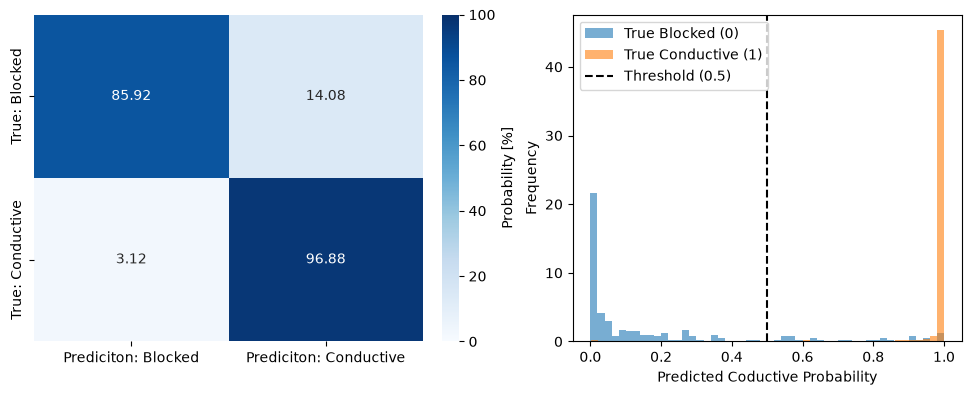

In [3]:
prob_cond = clf.predict(X_test_scaled, batch_size=4096, verbose=0).flatten()
pred_class = (prob_cond >= 0.5).astype(int)

print(classification_report(y_test_class, pred_class, target_names=["Blocked (0)", "Conductive (1)"], digits=4))
if len(np.unique(y_test_class)) > 1:
    print(f"ROC-AUC Score: {roc_auc_score(y_test_class, prob_cond):.4f}")

fig, axes = plt.subplots(1, 2, layout='constrained')
fig.set_figwidth(fig.get_figwidth()*1.5)
fig.set_figheight(fig.get_figheight()*0.8)

# --- Plot 1: Confusion Matrix ---
cm = confusion_matrix(y_test_class, pred_class, normalize="true") * 100
sns.heatmap(
    cm, annot=True, fmt=".2f", cmap="Blues", ax=axes[0],
    xticklabels=["Prediciton: Blocked", "Prediciton: Conductive"],
    yticklabels=["True: Blocked", "True: Conductive"],
    cbar_kws={"label": "Probability [%]"}, vmin=0, vmax=100
)

# --- Plot 2: Prediction ---
axes[1].hist(prob_cond[y_test_class == 0], bins=50, alpha=0.6, label="True Blocked (0)",  density=True)
axes[1].hist(prob_cond[y_test_class == 1], bins=50, alpha=0.6, label="True Conductive (1)",  density=True)
axes[1].axvline(0.5, color="black", linestyle="--", label="Threshold (0.5)")
axes[1].set_xlabel("Predicted Coductive Probability")
axes[1].set_ylabel("Frequency")
axes[1].legend()

I0000 00:00:1794571264.030903  413152 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_16', 20 bytes spill stores, 20 bytes spill loads

I0000 00:00:1794571264.190240  413159 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_16', 828 bytes spill stores, 828 bytes spill loads

I0000 00:00:1794571265.423805  413275 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_16', 20 bytes spill stores, 20 bytes spill loads

I0000 00:00:1794571265.565258  413274 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_16', 824 bytes spill stores, 824 bytes spill loads



=== REGRESSOR METRIKEN (Nur echt leitende Punkte) ===
R² (im arcsinh-Raum):        0.9689
MAE (im arcsinh-Raum):       0.3052
Medianer Relativer Fehler:   21.51 %

=== END-TO-END HURDLE METRIKEN (Alle Testpunkte inkl. Blockade) ===
R² Gesamt (Hard Gating):     0.9490
R² Gesamt (Soft Gating):     0.9482


Text(0, 0.5, 'Error ($\\hat{y}_{\\mathrm{trans}} - y_{\\mathrm{trans}}$)')

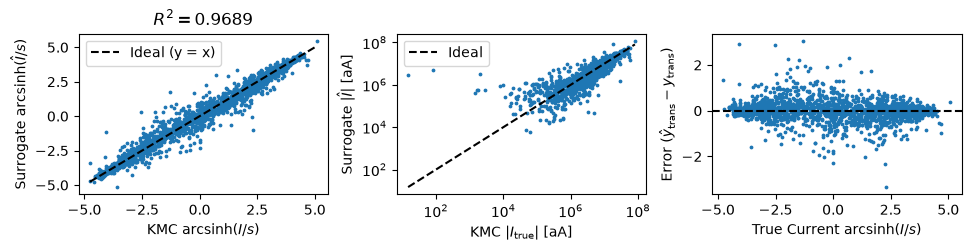

In [4]:
# 1. End-to-End Prediction (Hard Gating vs. Soft Gating)
I_pred_hard = surrogate.predict(X_test_raw, prob_threshold=0.3, soft_gating=False).flatten()
I_pred_soft = surrogate.predict(X_test_raw, soft_gating=True).flatten()

# Transform to arcsinh-Space
y_pred_trans_hard = np.arcsinh(I_pred_hard / scale_factor)
y_pred_trans_soft = np.arcsinh(I_pred_soft / scale_factor)

# 2. Regression Test
cond_mask = (y_test_class == 1.0)
y_reg_scaled_only = reg.predict(X_test_scaled[cond_mask], batch_size=4096, verbose=0)
y_reg_trans_only  = y_scaler.inverse_transform(y_reg_scaled_only).flatten()
I_reg_only        = np.sinh(y_reg_trans_only) * scale_factor

# Relative Deviation in conductive space
rel_error_cond = np.abs(I_reg_only - y_test_raw[cond_mask]) / np.maximum(np.abs(y_test_raw[cond_mask]), 1e-3)

print("=== REGRESSOR METRIKEN (Nur echt leitende Punkte) ===")
print(f"R² (im arcsinh-Raum):        {r2_score(y_test_trans[cond_mask], y_reg_trans_only):.4f}")
print(f"MAE (im arcsinh-Raum):       {mean_absolute_error(y_test_trans[cond_mask], y_reg_trans_only):.4f}")
print(f"Medianer Relativer Fehler:   {np.median(rel_error_cond)*100:.2f} %")

print("\n=== END-TO-END HURDLE METRIKEN (Alle Testpunkte inkl. Blockade) ===")
print(f"R² Gesamt (Hard Gating):     {r2_score(y_test_trans, y_pred_trans_hard):.4f}")
print(f"R² Gesamt (Soft Gating):     {r2_score(y_test_trans, y_pred_trans_soft):.4f}")

# ─── Parity Plots & Residuen ──────────────────────────────────
fig, axes = plt.subplots(1, 3, layout='constrained')
fig.set_figwidth(fig.get_figwidth()*1.5)
fig.set_figheight(fig.get_figheight()*0.5)

# --- Plot 1: Parity Plot of Regressors (arcsinh-Space) ---
axes[0].scatter(y_test_trans[cond_mask], y_reg_trans_only, s=3)
lims = [y_test_trans.min(), y_test_trans.max()]
axes[0].plot(lims, lims, "k--", lw=1.5, label="Ideal (y = x)")
axes[0].set_title(f"$R^2 = {r2_score(y_test_trans[cond_mask], y_reg_trans_only):.4f}$")
axes[0].set_xlabel("KMC $\\mathrm{arcsinh}(I / s)$")
axes[0].set_ylabel("Surrogate $\\mathrm{arcsinh}(\\hat{I} / s)$")
axes[0].legend()

# --- Plot 2: Log-Log Parity Plot - true physical Unit |I| [aA] ---
I_true_abs = np.abs(y_test_raw[cond_mask])
I_pred_abs = np.abs(I_reg_only)
axes[1].scatter(I_true_abs, I_pred_abs, s=3)
log_lims = [max(I_true_abs.min(), 0.1), I_true_abs.max()]
axes[1].plot(log_lims, log_lims, "k--", lw=1.5, label="Ideal")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("KMC $|I_{\\mathrm{true}}|$ [aA]")
axes[1].set_ylabel("Surrogate $|\\hat{I}|$ [aA]")
axes[1].legend()

# --- Plot 3: Residuen electric current ---
residuals_trans = y_reg_trans_only - y_test_trans[cond_mask]
axes[2].scatter(y_test_trans[cond_mask], residuals_trans, s=3)
axes[2].axhline(0, color="black", linestyle="--", lw=1.5)
axes[2].set_xlabel("True Current $\\mathrm{arcsinh}(I / s)$")
axes[2].set_ylabel("Error ($\\hat{y}_{\\mathrm{trans}} - y_{\\mathrm{trans}}$)")

In [6]:
# n_cpu = 10
# df_iv = pd.DataFrame()
# for i in range(n_cpu):
#     df_iv = pd.concat([df_iv, pd.read_csv(f"../data/iv_curve/Nx=3_Ny=3_Ne=8_part{i}.csv")], ignore_index=True)

df_iv = pd.read_csv(f"../data/iv_curve/Nx=3_Ny=3_Ne=8.csv")
df_iv = df_iv.sort_values(by='E0', ignore_index=True)       
df_iv.to_csv(f"../data/iv_curve/Nx=3_Ny=3_Ne=8.csv", index=0)

# Current
y_iv_kmc = df_iv['Observable'].values
y_e_iv_kmc = df_iv['Error'].values

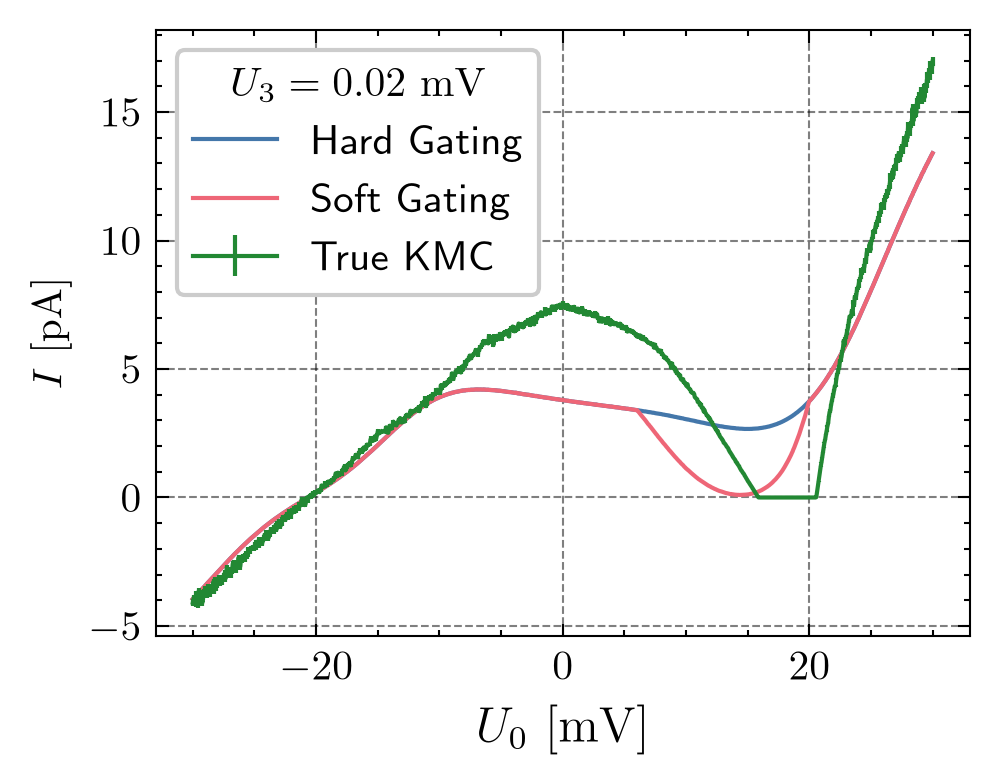

In [7]:
sweep_voltages = df_iv.iloc[:,:7].values
v_range = sweep_voltages[:,0]

# Feature Engineering
all_pairs = list(combinations(range(7), 2))
X_sweep_feat = add_physics_features(
    sweep_voltages, diff_pairs=all_pairs, sum_pairs=all_pairs, prod_pairs=[(5, 6), (3, 4)]
)

# Get Prediction for both gating types
I_sweep_hard = surrogate.predict(X_sweep_feat, prob_threshold=0.3, soft_gating=False).flatten()
I_sweep_soft = surrogate.predict(X_sweep_feat, soft_gating=True).flatten()

with plt.style.context(["science","bright", "grid"]):

    fig = plt.figure(dpi=300)
    ax  = fig.add_subplot()
    _   = ax.plot(v_range * 1e3, I_sweep_hard / 1e6, label="Hard Gating")
    _   = ax.plot(v_range * 1e3, I_sweep_soft / 1e6, label="Soft Gating")
    _   = ax.errorbar(v_range * 1e3, y_iv_kmc / 1e6, y_e_iv_kmc / 1e6, label='True KMC')
    _   = ax.set_xlabel("$U_0~[\\mathrm{mV}]$", fontsize='large')
    _   = ax.set_ylabel("$I~[\\mathrm{pA}]$")
    _   = ax.legend(title='$U_3 = 0.02~\\mathrm{mV}$')